## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Farha Arvadilla Damayanti
- NIM   : 241011402699
- Kelas : Reg B

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =    # isi dengan 2 digit terakhir NIM Anda

In [ ]:
# Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Bentuk X: (40, 1)
Bentuk y: (40,)


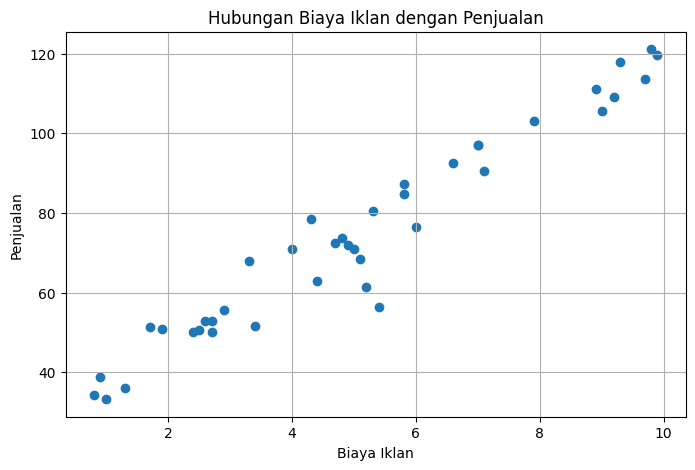

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Ads_Data.csv")

display(df.head())

print("Jumlah baris data:", len(df))

X = df[["BiayaIklan"]].to_numpy()
y = df["Penjualan"].to_numpy()

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

plt.figure(figsize=(8, 5))
plt.scatter(df["BiayaIklan"], df["Penjualan"])
plt.title("Hubungan Biaya Iklan dengan Penjualan")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.grid(True)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [2]:

RANDOM_STATE = 99

# Membagi data menjadi training (80%) dan testing (20%)
def train_test_split(X, y, test_size=0.2, random_state=99):
    np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_count = int(len(X) * test_size)

    test_indices = indices[:test_count]
    train_indices = indices[test_count:]

    X_train = X[train_indices]
    X_test = X[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)


Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3: Linear Regression dengan Normal Equation

# Menambahkan kolom 1 untuk menghitung intercept
X_train_bias = np.c_[np.ones((X_train.shape[0], 1)), X_train]

# Menghitung parameter menggunakan Normal Equation
theta = np.linalg.pinv(X_train_bias.T @ X_train_bias) @ X_train_bias.T @ y_train

# Memisahkan intercept dan koefisien
b = theta[0]
m = theta[1]

print("Intercept (b):", b)
print("Koefisien (m):", m)
print(f"Persamaan regresi: ŷ = {b:.4f} + {m:.4f}X")

Intercept (b): 29.1333090357398
Koefisien (m): 8.91996125563373
Persamaan regresi: ŷ = 29.1333 + 8.9200X


**Jawaban A3 (interpretasi):**
Nilai koefisien regresi (m) sebesar 8,91996 menunjukkan bahwa setiap kenaikan 1 satuan biaya iklan diperkirakan meningkatkan penjualan sebesar 8,92 satuan. Hal ini menunjukkan hubungan positif antara biaya iklan dan penjualan. Nilai intercept (\(b\)) sebesar 29,1333 berarti bahwa ketika biaya iklan bernilai nol, model memprediksi penjualan sebesar 29,13 satuan. Dengan demikian, persamaan regresi yang diperoleh adalah \(\hat{y} = 29,1333 + 8,9200X\).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def hitung_metrik(y_asli, y_prediksi):
    mae = np.mean(np.abs(y_asli - y_prediksi))
    mse = np.mean((y_asli - y_prediksi) ** 2)
    rmse = np.sqrt(mse)

    ss_res = np.sum((y_asli - y_prediksi) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else np.nan

    return mae, mse, rmse, r2

X_train_bias = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_test_bias = np.c_[np.ones((X_test.shape[0], 1)), X_test]

y_pred_train = X_train_bias @ theta
y_pred_test = X_test_bias @ theta

mae_train, mse_train, rmse_train, r2_train = hitung_metrik(
    y_train, y_pred_train
)

mae_test, mse_test, rmse_test, r2_test = hitung_metrik(
    y_test, y_pred_test
)

hasil_evaluasi = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Data Training": [mae_train, mse_train, rmse_train, r2_train],
    "Data Testing": [mae_test, mse_test, rmse_test, r2_test]
})

display(hasil_evaluasi.round(4))


,Metrik,Data Training,Data Testing
0,MAE,4.1726,6.2048
1,MSE,32.9262,49.7995
2,RMSE,5.7381,7.0569
3,R2,0.9503,0.8658


**Jawaban A4 (analisis):**
Berdasarkan hasil evaluasi, nilai MAE pada data training adalah 4,1726 dan pada data testing adalah 6,2048. Nilai RMSE pada data training sebesar 5,7381, sedangkan pada data testing sebesar 7,0569. Hal ini menunjukkan bahwa kesalahan prediksi pada data testing lebih besar dibandingkan data training.
Nilai R² pada data training sebesar 0,9503, yang berarti model dapat menjelaskan sekitar 95,03% variasi penjualan pada data training. Sementara itu, nilai R² pada data testing sebesar 0,8658, yang berarti model dapat menjelaskan sekitar 86,58% variasi penjualan pada data testing. Secara keseluruhan, model regresi ini memiliki kinerja yang cukup baik karena nilai R² pada data testing cukup tinggi. Namun, model masih menghasilkan kesalahan prediksi dan kinerjanya pada data testing lebih rendah daripada data training. Oleh karena itu, model masih dapat ditingkatkan agar prediksinya lebih akurat.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

HASIL NORMAL EQUATION (A3)
Intercept : 29.133309
Koefisien : 8.919961

Learning rate = 0.001
Intercept: 26.984000419101204
Koefisien: 9.257862144358528
MSE akhir: 34.12618136172022

Learning rate = 0.02
Intercept: 29.13330903573953
Koefisien: 8.919961255633774
MSE akhir: 32.926228222509565

Learning rate = 0.1
Intercept: 1.3893820637948046e+152
Koefisien: 8.837534736256373e+152
MSE akhir: 9.088571177240748e+305

TABEL PERBANDINGAN LEARNING RATE


/usr/local/lib/python3.13/dist-packages/pandas/core/internals/blocks.py:1920: RuntimeWarning: overflow encountered in multiply
  values = self.values.round(decimals)  # type: ignore[union-attr]


,Learning Rate,Intercept,Koefisien,MSE Akhir
0,0.001,2.698400e+01,9.257862e+00,34.126181
1,0.020,2.913331e+01,8.919961e+00,32.926228
2,0.100,1.389382e+152,8.837535e+152,inf


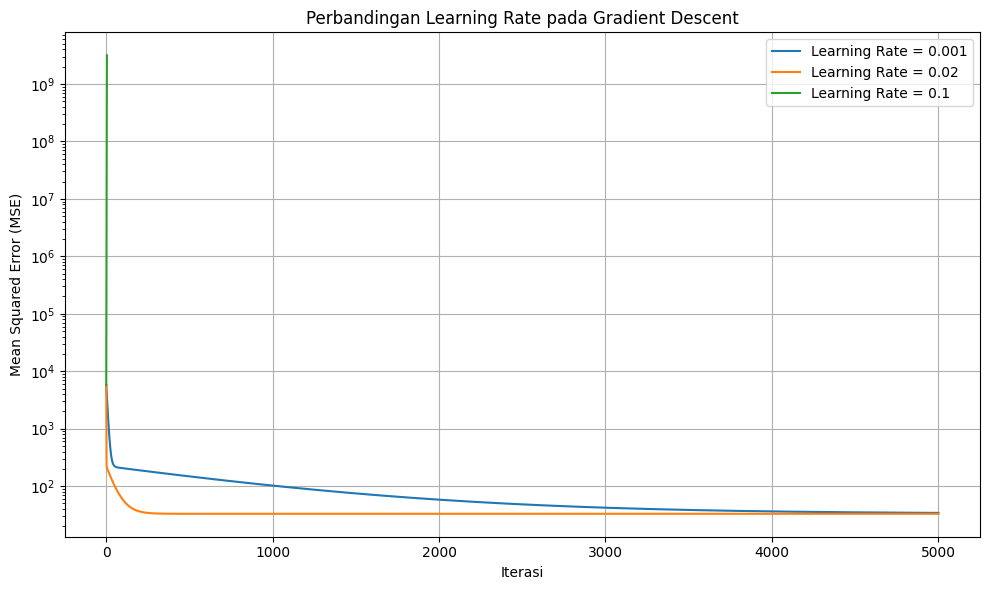

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.theta = None
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float).reshape(-1, 1)
        y = np.asarray(y, dtype=float).reshape(-1)

        X_bias = np.c_[np.ones((X.shape[0], 1)), X]

        self.theta = np.zeros(2)
        self.loss_history = []

        for i in range(self.n_iterations):
            y_pred = X_bias @ self.theta
            error = y_pred - y

            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

            # Hentikan jika perhitungan tidak stabil
            if not np.isfinite(mse) or not np.all(np.isfinite(error)):
                break

            gradient = (2 / len(y)) * (X_bias.T @ error)

            if not np.all(np.isfinite(gradient)):
                break

            self.theta -= self.learning_rate * gradient

            if not np.all(np.isfinite(self.theta)):
                break

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((X.shape[0], 1)), X]
        return X_bias @ self.theta


print("HASIL NORMAL EQUATION (A3)")
print(f"Intercept : {theta[0]:.6f}")
print(f"Koefisien : {theta[1]:.6f}")


learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
hasil_gd = []

for lr in learning_rates:
    print(f"\nLearning rate = {lr}")

    model = LinearRegressionGD(
        learning_rate=lr,
        n_iterations=5000
    )

    with np.errstate(over="ignore", invalid="ignore"):
        model.fit(X_train, y_train)

    models_gd[lr] = model

    b_gd, m_gd = model.theta

    losses = np.asarray(model.loss_history)
    valid_losses = losses[np.isfinite(losses)]

    if len(valid_losses) > 0 and np.all(np.isfinite(model.theta)):
        mse_akhir = valid_losses[-1]
    else:
        mse_akhir = np.nan

    hasil_gd.append({
        "Learning Rate": lr,
        "Intercept": b_gd,
        "Koefisien": m_gd,
        "MSE Akhir": mse_akhir
    })

    print("Intercept:", b_gd)
    print("Koefisien:", m_gd)
    print("MSE akhir:", mse_akhir)


tabel_gd = pd.DataFrame(hasil_gd)
print("\nTABEL PERBANDINGAN LEARNING RATE")
display(tabel_gd.round(6))


plt.figure(figsize=(10, 6))

for lr, model in models_gd.items():
    losses = np.asarray(model.loss_history)
    iterations = np.arange(1, len(losses) + 1)

    valid = (
        np.isfinite(losses)
        & (losses > 0)
        & (losses < 1e10)
    )

    if np.any(valid):
        plt.plot(
            iterations[valid],
            losses[valid],
            label=f"Learning Rate = {lr}"
        )

plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Perbandingan Learning Rate pada Gradient Descent")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**
Berdasarkan hasil pengujian, learning rate 0,001 menghasilkan MSE sebesar 34,1262, sedangkan learning rate 0,02 menghasilkan MSE sebesar 32,9262 dan parameter yang mendekati metode Normal Equation. Sementara itu, learning rate 0,1 menyebabkan nilai parameter dan MSE menjadi sangat besar sehingga proses pembelajaran tidak stabil. Dengan demikian, learning rate 0,02 merupakan pilihan terbaik karena menghasilkan MSE terendah dan model yang lebih stabil dibandingkan kedua nilai lainnya.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

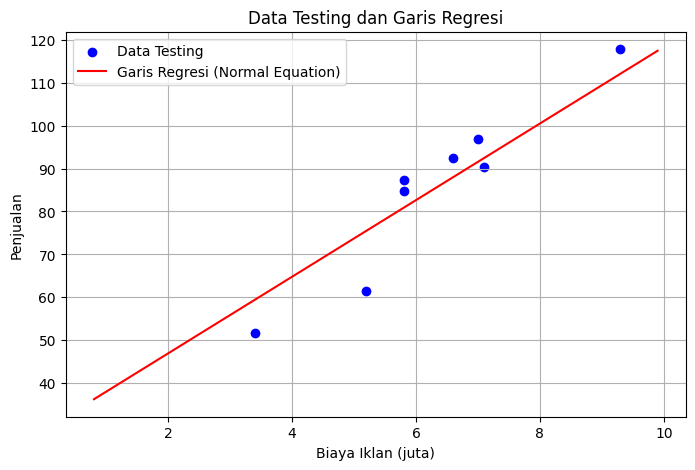

,Biaya Iklan (juta),Prediksi Penjualan
0,4.5,69.2731
1,7.0,91.5730
2,12.0,136.1728


In [8]:
# Jawaban A6
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test[:, 0],
    y_test,
    label="Data Testing",
    color="blue"
)

x_line = np.linspace(
    min(X_test[:, 0].min(), X_train[:, 0].min()),
    max(X_test[:, 0].max(), X_train[:, 0].max()),
    100
)

y_line = theta[0] + theta[1] * x_line

plt.plot(
    x_line,
    y_line,
    color="red",
    label="Garis Regresi (Normal Equation)"
)

plt.xlabel("Biaya Iklan (juta)")
plt.ylabel("Penjualan")
plt.title("Data Testing dan Garis Regresi")
plt.legend()
plt.grid(True)
plt.show()


biaya_iklan = np.array([4.5, 7, 12])

prediksi_penjualan = theta[0] + theta[1] * biaya_iklan

hasil_prediksi = pd.DataFrame({
    "Biaya Iklan (juta)": biaya_iklan,
    "Prediksi Penjualan": prediksi_penjualan
})

display(hasil_prediksi.round(4))


**Jawaban A6 (analisis):**
Berdasarkan grafik dan hasil prediksi, model regresi linear yang diperoleh dari metode Normal Equation pada Soal A3 menunjukkan hubungan positif antara biaya iklan dan penjualan. Artinya, semakin besar biaya iklan, penjualan diprediksi akan meningkat. Berdasarkan hasil perhitungan, biaya iklan sebesar 4,5 juta menghasilkan prediksi penjualan sebesar 69,2731, biaya iklan 7 juta menghasilkan prediksi sebesar 91,5730, dan biaya iklan 12 juta menghasilkan prediksi sebesar 136,1728. Namun, prediksi untuk biaya iklan 12 juta perlu diperhatikan karena berada di luar rentang data yang digunakan untuk melatih model, sehingga termasuk ekstrapolasi. Prediksi ekstrapolasi cenderung kurang dapat dipercaya karena hubungan antara biaya iklan dan penjualan belum tentu terus mengikuti pola linear pada nilai yang lebih tinggi. Oleh karena itu, hasil prediksi tersebut dapat digunakan sebagai perkiraan awal, tetapi diperlukan data tambahan untuk memastikan keakuratan prediksi pada biaya iklan yang lebih besar.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Lima Data Pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Email Spam dan Bukan Spam:
Bukan Spam (0): 35
Spam (1): 25

Bentuk X: (60, 2)
Bentuk y: (60,)


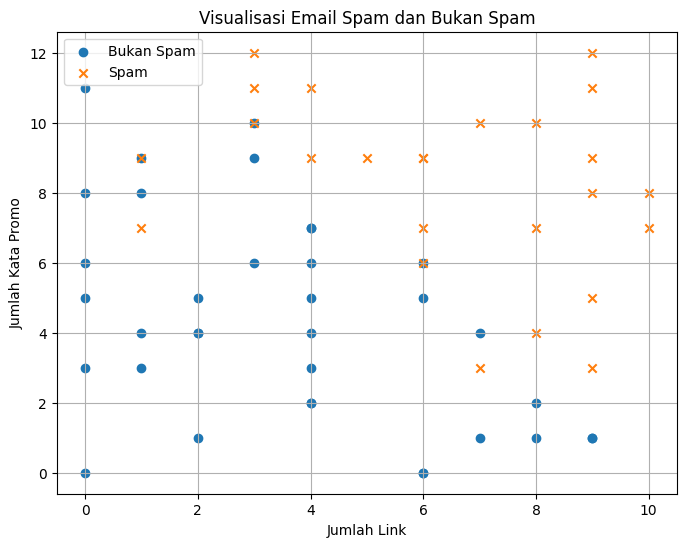

In [29]:
# Jawaban B1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_email = pd.read_csv("Email_Data.csv")

print("Lima Data Pertama:")
display(df_email.head())

print("\nJumlah Email Spam dan Bukan Spam:")
jumlah_email = df_email["Spam"].value_counts().reindex(
    [0, 1], fill_value=0
)

print("Bukan Spam (0):", jumlah_email[0])
print("Spam (1):", jumlah_email[1])

X = df_email[["JumlahLink", "KataPromo"]].to_numpy()
y = df_email["Spam"].to_numpy()

print("\nBentuk X:", X.shape)
print("Bentuk y:", y.shape)

plt.figure(figsize=(8, 6))

bukan_spam = df_email[df_email["Spam"] == 0]
plt.scatter(
    bukan_spam["JumlahLink"],
    bukan_spam["KataPromo"],
    label="Bukan Spam",
    marker="o"
)

spam = df_email[df_email["Spam"] == 1]
plt.scatter(
    spam["JumlahLink"],
    spam["KataPromo"],
    label="Spam",
    marker="x"
)

plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Visualisasi Email Spam dan Bukan Spam")
plt.legend()
plt.grid(True)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Jumlah data training: 45
Jumlah data testing: 15

Hasil Logistic Regression
Intercept (b) : -9.797352
Koefisien m1   : 0.793255
Koefisien m2   : 0.850867

Persamaan model:
P(Spam) = sigmoid(-9.797352 + (0.793255 * JumlahLink) + (0.850867 * KataPromo))


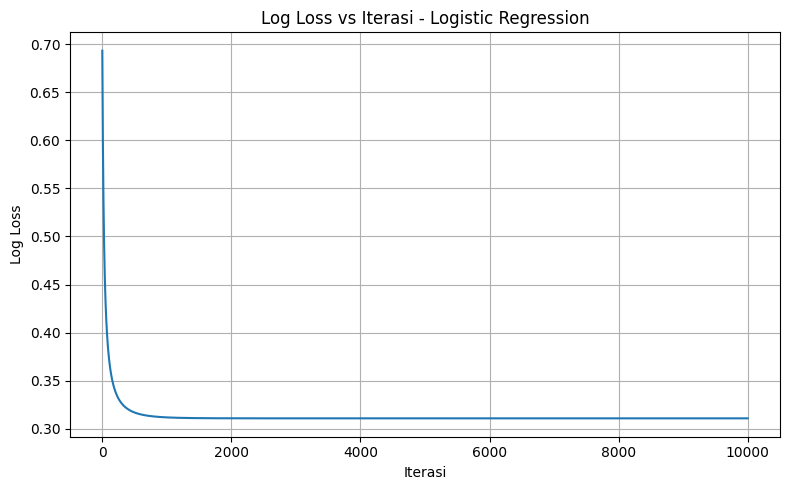


Log Loss awal : 0.693147
Log Loss akhir: 0.310808


In [12]:
# Jawaban B2
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 99

np.random.seed(RANDOM_STATE)
indices = np.random.permutation(len(X))

X_shuffled = X[indices]
y_shuffled = y[indices]

test_size = 0.25
n_test = int(len(X) * test_size)

X_test_B = X_shuffled[:n_test]
y_test_B = y_shuffled[:n_test]

X_train_B = X_shuffled[n_test:]
y_train_B = y_shuffled[n_test:]

print("Jumlah data training:", len(X_train_B))
print("Jumlah data testing:", len(X_test_B))


class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.b = 0.0
        self.coef_ = np.zeros(2)
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        # Standardisasi fitur agar training lebih stabil
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1

        X_scaled = (X - self.mean_) / self.std_

        n_samples, n_features = X_scaled.shape
        self.b = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history = []

        for i in range(self.n_iterations):
            z = self.b + X_scaled @ self.coef_
            y_pred = self.sigmoid(z)

            eps = 1e-12
            loss = -np.mean(
                y * np.log(y_pred + eps)
                + (1 - y) * np.log(1 - y_pred + eps)
            )
            self.loss_history.append(loss)

            error = y_pred - y
            db = np.mean(error)
            dw = (X_scaled.T @ error) / n_samples

            self.b -= self.learning_rate * db
            self.coef_ -= self.learning_rate * dw

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_scaled = (X - self.mean_) / self.std_
        z = self.b + X_scaled @ self.coef_
        return self.sigmoid(z)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)


model_logreg = LogisticRegressionGD(
    learning_rate=0.1,
    n_iterations=10000
)

model_logreg.fit(X_train_B, y_train_B)


m1 = model_logreg.coef_[0] / model_logreg.std_[0]
m2 = model_logreg.coef_[1] / model_logreg.std_[1]

b = (
    model_logreg.b
    - m1 * model_logreg.mean_[0]
    - m2 * model_logreg.mean_[1]
)

print("\nHasil Logistic Regression")
print(f"Intercept (b) : {b:.6f}")
print(f"Koefisien m1   : {m1:.6f}")
print(f"Koefisien m2   : {m2:.6f}")

print("\nPersamaan model:")
print(
    f"P(Spam) = sigmoid({b:.6f} "
    f"+ ({m1:.6f} * JumlahLink) "
    f"+ ({m2:.6f} * KataPromo))"
)


plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(model_logreg.loss_history) + 1),
    model_logreg.loss_history
)

plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss vs Iterasi - Logistic Regression")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nLog Loss awal :", round(model_logreg.loss_history[0], 6))
print("Log Loss akhir:", round(model_logreg.loss_history[-1], 6))


**Jawaban B2 (analisis):**
Data dibagi menjadi 45 data training (75%) dan 15 data testing (25%). Hasil pelatihan Logistic Regression menghasilkan intercept sebesar -9,797352, koefisien JumlahLink sebesar 0,793255, dan koefisien KataPromo sebesar 0,850867. Kedua koefisien bernilai positif, yang menunjukkan bahwa semakin banyak jumlah link dan kata promosi, semakin besar probabilitas email dikategorikan sebagai spam. Persamaan model yang diperoleh adalah \(P(Spam)=sigma(-9{,}797352+0{,}793255\,JumlahLink+0{,}850867\,KataPromo)\). Nilai Log Loss turun dari 0,693147 menjadi 0,310808 setelah 10.000 iterasi, yang menunjukkan bahwa model semakin baik dalam mempelajari pola data dan proses pembelajaran mengalami penurunan loss. Namun, kinerja model tetap perlu dievaluasi menggunakan data testing untuk mengetahui kemampuan klasifikasinya.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [15]:
# Jawaban B3
import numpy as np

y_pred_B = model_logreg.predict(X_test_B)

y_true = np.asarray(y_test_B).ravel().astype(int)
y_pred_B = np.asarray(y_pred_B).ravel().astype(int)

accuracy = np.mean(y_true == y_pred_B)

TN = np.sum((y_true == 0) & (y_pred_B == 0))
FP = np.sum((y_true == 0) & (y_pred_B == 1))
FN = np.sum((y_true == 1) & (y_pred_B == 0))
TP = np.sum((y_true == 1) & (y_pred_B == 1))

precision = TP / (TP + FP) if (TP + FP) != 0 else 0
recall = TP / (TP + FN) if (TP + FN) != 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0 else 0
)

print("=== HASIL EVALUASI MODEL ===")
print(f"Jumlah data testing: {len(y_true)}")
print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")

print("\nConfusion Matrix:")
print("                Prediksi")
print("              Bukan Spam  Spam")
print(f"Aktual Bukan Spam  {TN:5d}   {FP:5d}")
print(f"Aktual Spam       {FN:5d}   {TP:5d}")

print("\nDetail Confusion Matrix:")
print(f"True Negative (TN) : {TN}")
print(f"False Positive (FP): {FP}")
print(f"False Negative (FN): {FN}")
print(f"True Positive (TP) : {TP}")

print(f"\nPrecision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1_score:.4f}")


=== HASIL EVALUASI MODEL ===
Jumlah data testing: 15
Accuracy  : 0.9333 (93.33%)

Confusion Matrix:
                Prediksi
              Bukan Spam  Spam
Aktual Bukan Spam     11       0
Aktual Spam           1       3

Detail Confusion Matrix:
True Negative (TN) : 11
False Positive (FP): 0
False Negative (FN): 1
True Positive (TP) : 3

Precision : 1.0000
Recall    : 0.7500
F1-Score  : 0.8571


**Jawaban B3 (analisis):**
Berdasarkan hasil evaluasi, model Logistic Regression memperoleh accuracy 93,33%, precision 100%, recall 75%, dan F1-score 85,71%. Model berhasil memprediksi 11 email bukan spam dan 3 email spam dengan benar, tetapi masih terdapat 1 email spam yang salah diklasifikasikan sebagai bukan spam. False Positive (FP) terjadi ketika email bukan spam dianggap sebagai spam, sedangkan False Negative (FN) terjadi ketika email spam dianggap sebagai bukan spam. Menurut saya, kedua kesalahan tersebut dapat merugikan pengguna karena email penting bisa masuk ke folder spam atau email berbahaya lolos ke kotak masuk. Secara keseluruhan, model sudah memiliki performa yang baik, tetapi masih perlu ditingkatkan agar dapat mendeteksi lebih banyak email spam.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary:
x2 = -(-9.7974 + (0.7933 * x1)) / (0.8509)


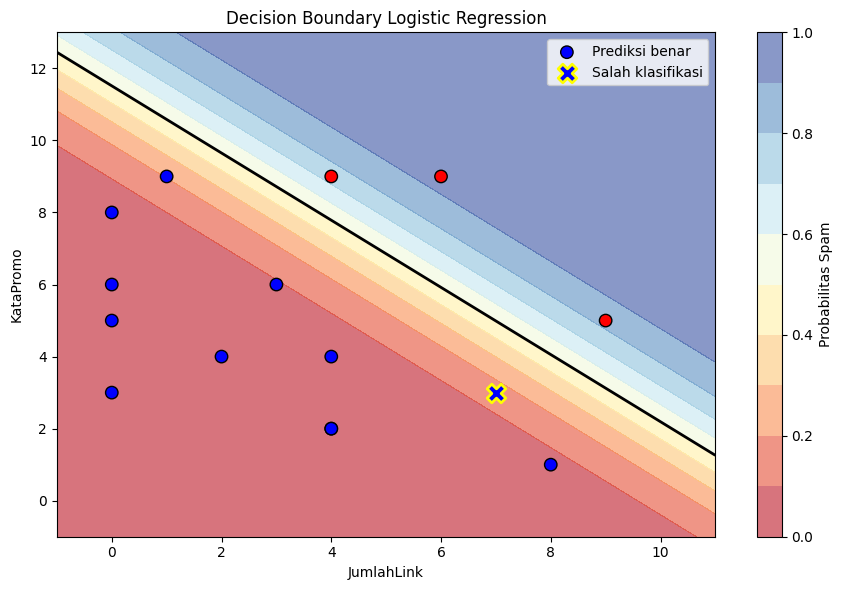


Data testing yang salah diklasifikasikan:
Data ke-10: JumlahLink=7, KataPromo=3, Aktual=1, Prediksi=0


In [20]:
# Jawaban B4
import numpy as np
import matplotlib.pyplot as plt

X_test = np.asarray(X_test_B)
y_test = np.asarray(y_test_B).ravel().astype(int)
y_pred = model_logreg.predict(X_test)

m1 = model_logreg.coef_[0] / model_logreg.std_[0]
m2 = model_logreg.coef_[1] / model_logreg.std_[1]

b = (model_logreg.b
     - m1 * model_logreg.mean_[0]
     - m2 * model_logreg.mean_[1])

print("Persamaan Decision Boundary:")
print(f"x2 = -({b:.4f} + ({m1:.4f} * x1)) / ({m2:.4f})")

x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_logreg.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(9, 6))
plt.contourf(
    xx1, xx2, probs,
    levels=np.linspace(0, 1, 11),
    cmap="RdYlBu",
    alpha=0.6
)
plt.colorbar(label="Probabilitas Spam")

plt.contour(
    xx1, xx2, probs,
    levels=[0.5],
    colors="black",
    linewidths=2
)

benar = y_test == y_pred
plt.scatter(
    X_test[benar, 0], X_test[benar, 1],
    c=y_test[benar], cmap="bwr",
    edgecolors="black", s=80,
    label="Prediksi benar"
)

salah = y_test != y_pred
plt.scatter(
    X_test[salah, 0], X_test[salah, 1],
    c=y_test[salah], cmap="bwr",
    edgecolors="yellow", linewidths=2,
    s=180, marker="X",
    label="Salah klasifikasi"
)

plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.title("Decision Boundary Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

print("\nData testing yang salah diklasifikasikan:")
if np.any(salah):
    for i in np.where(salah)[0]:
        print(
            f"Data ke-{i+1}: JumlahLink={X_test[i,0]}, "
            f"KataPromo={X_test[i,1]}, "
            f"Aktual={y_test[i]}, Prediksi={y_pred[i]}"
        )
else:
    print("Tidak ada data yang salah diklasifikasikan.")


**Jawaban B4 (analisis):**
Berdasarkan hasil perhitungan, persamaan decision boundary yang diperoleh adalah
x^2 =
−
(
−
9,7974
+
0,7933x1
)
/
0,8509
. Garis ini menjadi batas pemisah antara klasifikasi email spam dan bukan spam berdasarkan probabilitas 0,5. Dari hasil pengujian data testing, terdapat satu data yang salah diklasifikasikan, yaitu data ke-10 dengan jumlah link sebanyak 7 dan kata promo sebanyak 3. Data tersebut sebenarnya termasuk spam, tetapi diprediksi sebagai bukan spam oleh model. Kesalahan ini termasuk False Negative (FN), yaitu ketika email spam tidak berhasil terdeteksi. Hal ini menunjukkan bahwa model sudah mampu mengklasifikasikan sebagian besar data dengan benar, tetapi masih perlu ditingkatkan agar dapat mendeteksi email spam dengan lebih baik.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [17]:
# Jawaban B5
import numpy as np
import pandas as pd

prob_spam = model_logreg.predict_proba(X_test_B)

thresholds = [0.3, 0.5, 0.7]
hasil_threshold = []

y_true = np.asarray(y_test_B).ravel().astype(int)

for threshold in thresholds:
    y_pred_threshold = (prob_spam >= threshold).astype(int)

    TN = np.sum((y_true == 0) & (y_pred_threshold == 0))
    FP = np.sum((y_true == 0) & (y_pred_threshold == 1))
    FN = np.sum((y_true == 1) & (y_pred_threshold == 0))
    TP = np.sum((y_true == 1) & (y_pred_threshold == 1))

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    hasil_threshold.append({
        "Threshold": threshold,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
        "Precision": precision,
        "Recall": recall
    })

tabel_threshold = pd.DataFrame(hasil_threshold)

print("=== PERBANDINGAN THRESHOLD ===")
display(tabel_threshold.round(4))


=== PERBANDINGAN THRESHOLD ===


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,11,0,1,3,1.0,0.75
1,0.5,11,0,1,3,1.0,0.75
2,0.7,11,0,1,3,1.0,0.75


**Jawaban B5 (analisis):**
Jawaban B5 (analisis):

Berdasarkan hasil eksperimen, threshold 0,3, 0,5, dan 0,7 menghasilkan nilai confusion matrix, precision, dan recall yang sama. Model memperoleh TN = 11, FP = 0, FN = 1, dan TP = 3, dengan precision sebesar 100% dan recall sebesar 75%. Hal ini menunjukkan bahwa perubahan threshold pada ketiga nilai tersebut belum mengubah hasil klasifikasi data testing. Secara umum, threshold yang lebih rendah membuat model lebih mudah mendeteksi email spam, tetapi berpotensi meningkatkan kesalahan dalam menandai email bukan spam sebagai spam. Sebaliknya, threshold yang lebih tinggi membuat model lebih ketat dalam mendeteksi spam sehingga berpotensi menyebabkan lebih banyak email spam tidak terdeteksi. Berdasarkan hasil B3, saya memilih threshold 0,3 apabila tujuan utama filter adalah mengurangi email spam yang lolos ke kotak masuk. Namun, karena hasil ketiga threshold sama, belum ada perbedaan performa pada data testing ini, sehingga pengujian dengan data yang lebih banyak diperlukan untuk menentukan threshold yang paling sesuai.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [18]:
# Jawaban B6
import numpy as np
import pandas as pd

X_email_baru = np.array([
    [1, 2],    # E1
    [5, 6],    # E2
    [9, 10],   # E3
    [2, 11]    # E4
])

nama_email = ["E1", "E2", "E3", "E4"]
threshold = 0.3

probabilitas = model_logreg.predict_proba(X_email_baru)

prediksi = (probabilitas >= threshold).astype(int)

hasil_B6 = pd.DataFrame({
    "Email": nama_email,
    "JumlahLink": X_email_baru[:, 0],
    "KataPromo": X_email_baru[:, 1],
    "Probabilitas Spam": probabilitas.round(4),
    "Probabilitas (%)": (probabilitas * 100).round(2),
    "Prediksi Kelas": [
        "Spam" if p == 1 else "Bukan Spam"
        for p in prediksi
    ]
})

print("HASIL PREDIKSI EMAIL BARU (Threshold = 0.3)")
display(hasil_B6)


HASIL PREDIKSI EMAIL BARU (Threshold = 0.3)


,Email,JumlahLink,KataPromo,Probabilitas Spam,Probabilitas (%),Prediksi Kelas
0,E1,1,2,0.0007,0.07,Bukan Spam
1,E2,5,6,0.3261,32.61,Spam
2,E3,9,10,0.9971,99.71,Spam
3,E4,2,11,0.7593,75.93,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kategori, misalnya email spam atau bukan spam. Kata regression mengacu pada cara model menghitung hubungan antara fitur dan hasil prediksi. Fungsi sigmoid mengubah hasil perhitungan menjadi probabilitas antara 0 dan 1. Probabilitas tersebut kemudian digunakan untuk menentukan kelas berdasarkan threshold yang ditetapkan.

**Jawaban C2:**
Normal Equation menghitung koefisien model secara langsung menggunakan operasi matematika tanpa proses iterasi. Sementara itu, Gradient Descent mencari koefisien terbaik secara bertahap dengan memperbarui nilai parameter untuk mengurangi kesalahan prediksi. Normal Equation cocok untuk dataset berukuran kecil hingga sedang. Gradient Descent lebih cocok digunakan pada dataset yang besar karena dapat lebih efisien dalam penggunaan komputasi jika parameternya diatur dengan tepat.

**Jawaban C3:**
Data testing digunakan untuk mengetahui kemampuan model dalam memprediksi data baru yang belum pernah dipelajari saat training. Jika evaluasi hanya dilakukan pada data training, hasilnya bisa terlihat bagus tetapi belum tentu akurat pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga kurang mampu memprediksi data yang berbeda. Oleh karena itu, data testing diperlukan untuk menilai kemampuan generalisasi model.

**Jawaban C4:**
Karena Linear Regression menggunakan MSE untuk menghitung rata-rata kuadrat selisih antara nilai aktual dan hasil prediksi berupa angka kontinu. Sementara itu, Logistic Regression menggunakan log loss karena menghasilkan probabilitas untuk kelas tertentu. Log loss memberikan penalti lebih besar ketika model memberikan probabilitas yang tinggi pada kelas yang salah. Dengan demikian, kedua fungsi loss tersebut disesuaikan dengan jenis output dan tujuan masing-masing model.

**Jawaban C5:**
Hasil dapat berbeda karena pembagian data training dan testing mungkin tidak sama. Selain itu, perbedaan nilai random state, learning rate, jumlah iterasi, dan inisialisasi parameter juga dapat memengaruhi hasil model. Perbedaan preprocessing atau standardisasi data juga bisa menghasilkan koefisien dan akurasi yang berbeda. Oleh karena itu, pengaturan eksperimen perlu dibuat konsisten agar hasilnya dapat dibandingkan secara adil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [28]:
# Perbandingan Linear Regression dan sklearn.linear_model.LinearRegression
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

X = df[["BiayaIklan"]].to_numpy()
y = df["Penjualan"].to_numpy()

def train_test_split(X, y, test_size=0.2, random_state=99):
    np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_count = int(len(X) * test_size)

    test_indices = indices[:test_count]
    train_indices = indices[test_count:]

    X_train = X[train_indices]
    X_test = X[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=99
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

X_train_bias = np.c_[
    np.ones((X_train.shape[0], 1)), X_train
]

theta = (
    np.linalg.pinv(X_train_bias.T @ X_train_bias)
    @ X_train_bias.T
    @ y_train
)

model_sklearn = LinearRegression()
model_sklearn.fit(X_train, y_train)

X_test_bias = np.c_[
    np.ones((X_test.shape[0], 1)), X_test
]

y_pred_manual = X_test_bias @ theta
y_pred_sklearn = model_sklearn.predict(X_test)

tabel_koefisien = pd.DataFrame({
    "Parameter": ["Intercept", "Koefisien"],
    "Linear Regression": [
        theta[0],
        theta[1]
    ],
    "sklearn.linear_model.LinearRegression": [
        model_sklearn.intercept_,
        model_sklearn.coef_[0]
    ]
})

print("\n=== PERBANDINGAN KOEFISIEN ===")
display(tabel_koefisien.round(6))

def evaluasi(y_asli, y_prediksi):
    mae = mean_absolute_error(y_asli, y_prediksi)
    mse = mean_squared_error(y_asli, y_prediksi)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_asli, y_prediksi)

    return [mae, mse, rmse, r2]

tabel_evaluasi = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Linear Regression": evaluasi(
        y_test, y_pred_manual
    ),
    "sklearn.linear_model.LinearRegression": evaluasi(
        y_test, y_pred_sklearn
    )
})

print("\n=== PERBANDINGAN HASIL EVALUASI DATA TESTING ===")
display(tabel_evaluasi.round(6))

tabel_prediksi = pd.DataFrame({
    "Penjualan Aktual": y_test,
    "Linear Regression": y_pred_manual,
    "sklearn.linear_model.LinearRegression": y_pred_sklearn
})

print("\n=== PERBANDINGAN HASIL PREDIKSI ===")
display(tabel_prediksi.round(4))

selisih_maksimum = np.max(
    np.abs(y_pred_manual - y_pred_sklearn)
)

print("\nSelisih maksimum prediksi:", selisih_maksimum)

if np.allclose(y_pred_manual, y_pred_sklearn):
    print(
        "Kesimpulan: Kedua model menghasilkan prediksi "
        "yang sama atau sangat mendekati."
    )
else:
    print(
        "Kesimpulan: Terdapat perbedaan hasil prediksi "
        "antara kedua model."
    )


Shape X_train: (32, 1)
Shape X_test : (8, 1)

=== PERBANDINGAN KOEFISIEN ===


,Parameter,Linear Regression,sklearn.linear_model.LinearRegression
0,Intercept,29.133309,29.133309
1,Koefisien,8.919961,8.919961



=== PERBANDINGAN HASIL EVALUASI DATA TESTING ===


,Metrik,Linear Regression,sklearn.linear_model.LinearRegression
0,MAE,6.204764,6.204764
1,MSE,49.799464,49.799464
2,RMSE,7.056874,7.056874
3,R2,0.865828,0.865828



=== PERBANDINGAN HASIL PREDIKSI ===


,Penjualan Aktual,Linear Regression,sklearn.linear_model.LinearRegression
0,84.7,80.8691,80.8691
1,117.8,112.0889,112.0889
2,97.0,91.5730,91.5730
3,61.5,75.5171,75.5171
4,92.4,88.0051,88.0051
5,90.4,92.4650,92.4650
6,87.3,80.8691,80.8691
7,51.7,59.4612,59.4612



Selisih maksimum prediksi: 4.263256414560601e-14
Kesimpulan: Kedua model menghasilkan prediksi yang sama atau sangat mendekati.


In [32]:
# Perbandingan Logistic Regression dengan Scikit-learn

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    log_loss
)
from IPython.display import display

# 1. Membaca data
df_email = pd.read_csv("Email_Data.csv")

X = df_email[["JumlahLink", "KataPromo"]].to_numpy()
y = df_email["Spam"].to_numpy()

print("Jumlah data:", len(df_email))
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

# 2. Membagi data training dan testing
RANDOM_STATE = 99
TEST_SIZE = 0.25

np.random.seed(RANDOM_STATE)

indices = np.random.permutation(len(X))
test_size = int(len(X) * TEST_SIZE)

test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_train_B = X[train_indices]
X_test_B = X[test_indices]
y_train_B = y[train_indices]
y_test_B = y[test_indices]

print("\nJumlah data training:", len(X_train_B))
print("Jumlah data testing:", len(X_test_B))

# 3. Implementasi Logistic Regression dengan Gradient Descent
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_[self.std_ == 0] = 1

        X_scaled = (X - self.mean_) / self.std_

        n_samples, n_features = X_scaled.shape

        self.intercept_scaled_ = 0.0
        self.coef_scaled_ = np.zeros(n_features)

        for _ in range(self.n_iterations):
            z = (
                X_scaled @ self.coef_scaled_
                + self.intercept_scaled_
            )

            y_pred = self.sigmoid(z)
            error = y_pred - y

            dw = (X_scaled.T @ error) / n_samples
            db = np.mean(error)

            self.coef_scaled_ -= self.learning_rate * dw
            self.intercept_scaled_ -= self.learning_rate * db

        self.coef_ = self.coef_scaled_ / self.std_

        self.intercept_ = (
            self.intercept_scaled_
            - np.sum(
                self.coef_scaled_ * self.mean_ / self.std_
            )
        )

        return self

    def predict_proba(self, X):
        X_scaled = (X - self.mean_) / self.std_

        z = (
            X_scaled @ self.coef_scaled_
            + self.intercept_scaled_
        )

        return self.sigmoid(z)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)


# 4. Melatih kedua model dengan data training yang sama
model_logreg = LogisticRegressionGD(
    learning_rate=0.1,
    n_iterations=10000
)

model_logreg.fit(X_train_B, y_train_B)

model_sklearn = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=10000,
    random_state=RANDOM_STATE
)

model_sklearn.fit(X_train_B, y_train_B)

# 5. Perbandingan koefisien
tabel_koefisien = pd.DataFrame({
    "Parameter": [
        "Intercept",
        "Koefisien JumlahLink",
        "Koefisien KataPromo"
    ],
    "Logistic Regression": [
        model_logreg.intercept_,
        model_logreg.coef_[0],
        model_logreg.coef_[1]
    ],
    "sklearn.linear_model.LogisticRegression": [
        model_sklearn.intercept_[0],
        model_sklearn.coef_[0][0],
        model_sklearn.coef_[0][1]
    ]
})

print("\n=== PERBANDINGAN KOEFISIEN ===")
display(tabel_koefisien.round(6))

# 6. Prediksi pada data testing
prob_logreg = model_logreg.predict_proba(X_test_B)
pred_logreg = model_logreg.predict(X_test_B, threshold=0.5)

prob_sklearn = model_sklearn.predict_proba(X_test_B)[:, 1]
pred_sklearn = model_sklearn.predict(X_test_B)

# 7. Menghitung metrik evaluasi
def hitung_evaluasi(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Log Loss": log_loss(
            y_true,
            np.clip(y_prob, 1e-15, 1 - 1e-15),
            labels=[0, 1]
        )
    }


evaluasi_logreg = hitung_evaluasi(
    y_test_B, pred_logreg, prob_logreg
)

evaluasi_sklearn = hitung_evaluasi(
    y_test_B, pred_sklearn, prob_sklearn
)

tabel_evaluasi = pd.DataFrame({
    "Metrik": list(evaluasi_logreg.keys()),
    "Logistic Regression": list(evaluasi_logreg.values()),
    "sklearn.linear_model.LogisticRegression": list(
        evaluasi_sklearn.values()
    )
})

print("\n=== PERBANDINGAN HASIL EVALUASI ===")
display(tabel_evaluasi.round(6))

# 8. Perbandingan Confusion Matrix
cm_logreg = confusion_matrix(
    y_test_B, pred_logreg, labels=[0, 1]
)

cm_sklearn = confusion_matrix(
    y_test_B, pred_sklearn, labels=[0, 1]
)

tabel_confusion = pd.DataFrame({
    "Komponen": [
        "True Negative (TN)",
        "False Positive (FP)",
        "False Negative (FN)",
        "True Positive (TP)"
    ],
    "Logistic Regression": [
        cm_logreg[0, 0],
        cm_logreg[0, 1],
        cm_logreg[1, 0],
        cm_logreg[1, 1]
    ],
    "sklearn.linear_model.LogisticRegression": [
        cm_sklearn[0, 0],
        cm_sklearn[0, 1],
        cm_sklearn[1, 0],
        cm_sklearn[1, 1]
    ]
})

print("\n=== PERBANDINGAN CONFUSION MATRIX ===")
display(tabel_confusion)

# 9. Perbandingan prediksi data testing
tabel_prediksi = pd.DataFrame({
    "JumlahLink": X_test_B[:, 0],
    "KataPromo": X_test_B[:, 1],
    "Spam Aktual": y_test_B,
    "Prediksi Logistic Regression": pred_logreg,
    "Probabilitas Logistic Regression": prob_logreg,
    "Prediksi sklearn": pred_sklearn,
    "Probabilitas sklearn": prob_sklearn
})

print("\n=== PERBANDINGAN PREDIKSI DATA TESTING ===")
display(tabel_prediksi.round(6))


Jumlah data: 60
Bentuk X: (60, 2)
Bentuk y: (60,)

Jumlah data training: 45
Jumlah data testing: 15

=== PERBANDINGAN KOEFISIEN ===


,Parameter,Logistic Regression,sklearn.linear_model.LogisticRegression
0,Intercept,-9.797352,-8.703149
1,Koefisien JumlahLink,0.793255,0.693354
2,Koefisien KataPromo,0.850867,0.761860



=== PERBANDINGAN HASIL EVALUASI ===


,Metrik,Logistic Regression,sklearn.linear_model.LogisticRegression
0,Accuracy,0.933333,0.933333
1,Precision,1.000000,1.000000
2,Recall,0.750000,0.750000
3,F1-Score,0.857143,0.857143
4,Log Loss,0.196137,0.205625



=== PERBANDINGAN CONFUSION MATRIX ===


,Komponen,Logistic Regression,sklearn.linear_model.LogisticRegression
0,True Negative (TN),11,11
1,False Positive (FP),0,0
2,False Negative (FN),1,1
3,True Positive (TP),3,3



=== PERBANDINGAN PREDIKSI DATA TESTING ===


,JumlahLink,KataPromo,Spam Aktual,Prediksi Logistic Regression,Probabilitas Logistic Regression,Prediksi sklearn,Probabilitas sklearn
0,0,5,0,0,0.003899,0,0.007437
1,4,4,0,0,0.038388,0,0.053036
2,0,8,0,0,0.047861,0,0.068608
3,0,3,0,0,0.000713,0,0.001630
4,0,6,0,0,0.009084,0,0.015797
5,1,9,0,0,0.206477,0,0.239932
6,6,9,1,1,0.932137,1,0.910006
7,3,6,0,0,0.090102,0,0.113858
8,4,9,1,1,0.737588,1,0.716468
9,7,3,1,0,0.155517,0,0.173060


**Jawaban Bonus (analisis):**
Berdasarkan hasil perbandingan Linear Regression dengan sklearn.linear_model.LinearRegression, kedua model menghasilkan nilai koefisien yang sama, yaitu intercept sebesar 29,133309 dan koefisien sebesar 8,919961. Hasil evaluasi juga menunjukkan nilai MAE sebesar 6,204764, MSE sebesar 49,799464, RMSE sebesar 7,056874, dan R² sebesar 0,865828. Nilai R² menunjukkan bahwa model mampu menjelaskan sekitar 86,58% variasi penjualan pada data testing. Selain itu, hasil prediksi kedua model sama pada seluruh data pengujian, meskipun masih terdapat selisih antara nilai penjualan aktual dan hasil prediksi. Hal ini menunjukkan bahwa penerapan algoritma Linear Regression menghasilkan hasil yang sesuai dengan model dari Scikit-learn.

Pada perbandingan Logistic Regression dengan sklearn.linear_model.LogisticRegression, terdapat perbedaan nilai koefisien dan probabilitas prediksi karena kedua model menggunakan pengaturan dan proses optimasi yang berbeda. Model Logistic Regression yang dibuat menggunakan Gradient Descent dengan standardisasi fitur tanpa regularisasi, sedangkan Scikit-learn menggunakan regularisasi L2 tanpa standardisasi fitur secara eksplisit. Meskipun demikian, kedua model menghasilkan Accuracy sebesar 93,33%, Precision 100%, Recall 75%, dan F1-Score 85,71%. Berdasarkan confusion matrix, kedua model berhasil mengklasifikasikan 14 dari 15 data testing dengan benar, dengan satu email spam yang salah diprediksi sebagai bukan spam. Nilai Log Loss model pertama sebesar 0,196137 juga lebih rendah dibandingkan Scikit-learn sebesar 0,205625, sehingga model pertama menghasilkan probabilitas prediksi yang sedikit lebih baik berdasarkan metrik tersebut.

Secara keseluruhan, kedua percobaan menunjukkan bahwa penerapan algoritma regresi dapat menghasilkan performa yang sebanding dengan Scikit-learn. Pada Linear Regression, nilai koefisien, evaluasi, dan prediksi kedua model identik. Sementara itu, pada Logistic Regression, kedua model menghasilkan kelas prediksi dan metrik klasifikasi yang sama, meskipun terdapat perbedaan pada nilai koefisien dan probabilitasnya.